# Counting barnacles

Counting 1,000+ barnacles per photo by hand is slow. My idea: instead of counting, have a model put a dot on every live barnacle, and let a person just check the dots it isn't sure about. The count is the number of dots, and the dots are saved, so you can always go back and see what was counted.

I split the problem into a few pieces:

| Step | In | Out | Done? |
|---|---|---|---|
| Find the frame | photo | the inner square, straightened out | yes |
| Detect barnacles | the square | a dot (x, y, confidence) per barnacle | yes, main focus |
| Pick dots to review | dots + confidences | the ones worth a second look | simulated |
| Review tool | photo + dots | corrected count | no |

Why dots? A bare count can't be checked without recounting, and full outlines are a lot more work than counting needs.

The training runs take about an hour, so `python -m barnacles.experiments` does them once and saves the results to `results/`. This notebook just loads them, so it runs in under a minute.

In [1]:
%config InlineBackend.figure_formats = ["jpeg"]  # the figures are mostly photos; keeps the notebook small

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from barnacles import data, frame, evaluate
from barnacles.experiments import load_labeled, BOTTOM, BUDGETS, SEEDS, RESULTS

samples = load_labeled()  # frame detection + rectification + labels for img1, img2
detections, labeled_counts = evaluate.load_results(RESULTS)
held_out = {name: data.crop(s.image, s.points, BOTTOM)[1] for name, s in samples.items()}

## The labels

The masks don't outline whole shells. They outline the operculum (the little "door" on top) of *live* barnacles only. Empty shells aren't labeled, so the model can't just find round things. I turned each outline into a point: its center plus a radius.

,labeled barnacles,median radius (px)
img1,1732.0,7.6
img2,397.0,11.9


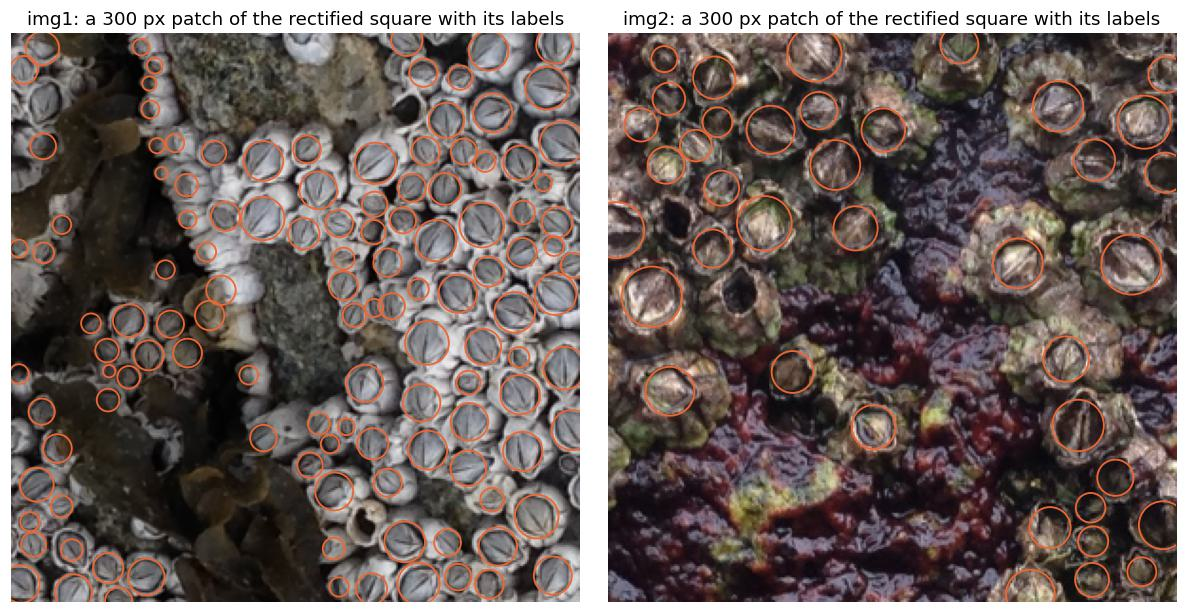

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, (name, s) in zip(axes, samples.items()):
    patch, pts = data.crop(s.image, s.points, (300, 300, 600, 600))
    ax.imshow(patch)
    for x, y, r in pts:
        ax.add_patch(plt.Circle((x, y), r, fill=False, color=evaluate.ORANGE, linewidth=1.2))
    ax.set_title(f"{name}: a 300 px patch of the rectified square with its labels")
    ax.axis("off")
fig.tight_layout()

pd.DataFrame(
    {name: {"labeled barnacles": len(s.points), "median radius (px)": np.median(s.points[:, 2]).round(1)}
     for name, s in samples.items()}
).T

The two photos look really different. img1 is dry and bright with small, packed barnacles; img2 is wet and dark with bigger, sparser ones. Even the contrast flips: the operculum is darker than its surroundings in img1 and lighter in img2. That ends up mattering a lot.

## Finding the frame

The wire is a teal that nothing else in the photos is close to, so a color threshold finds it. The inner square is the biggest area fully enclosed by wire. I then warp it to a 1024×1024 square. Since the frame is the only thing of known size in the picture, this also makes every photo the same scale (roughly 0.1 mm per pixel), no matter how far away the camera was.

,annotated,inside detected square
img1,1732,1732
img2,397,397


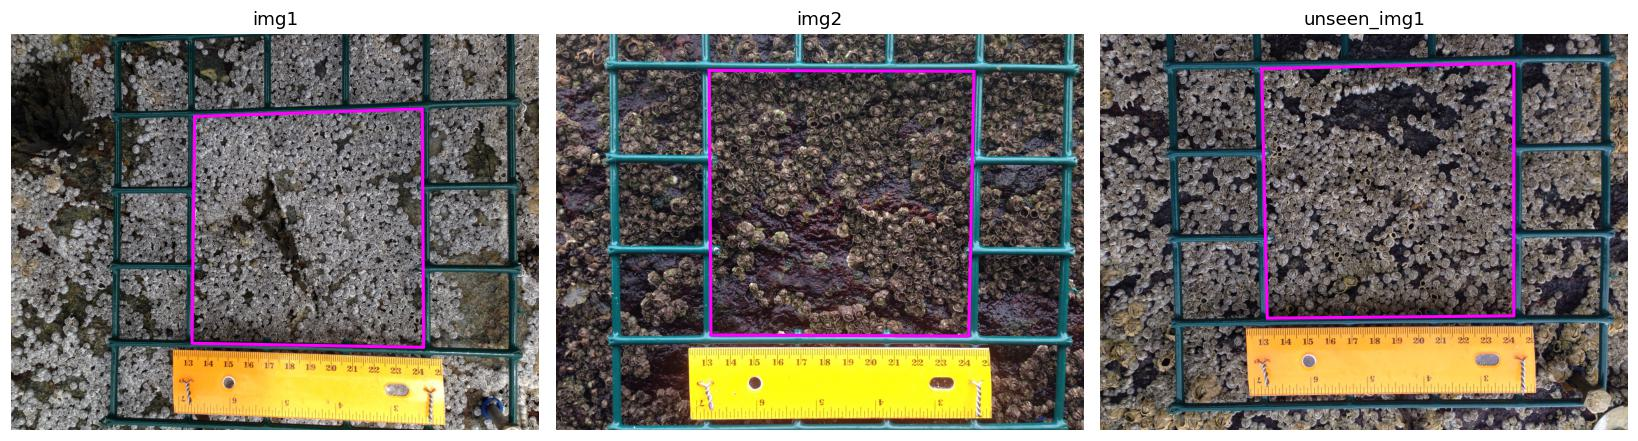

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, name in zip(axes, ["img1", "img2", "unseen_img1"]):
    rgb = data.load_rgb(data.DATA_DIR / f"{name}.png")
    corners = frame.find_inner_square(rgb)
    ax.imshow(rgb)
    ax.plot(*np.vstack([corners, corners[:1]]).T, color="magenta", linewidth=2)
    ax.axis("off")
    ax.set_title(name)
fig.tight_layout()

raw_counts = {n: len(data.points_from_mask(data.DATA_DIR / f"mask{n[-1]}.png")) for n in samples}
pd.DataFrame(
    {n: {"annotated": raw_counts[n], "inside detected square": len(s.points)} for n, s in samples.items()}
).T

Every labeled barnacle lands inside the detected square, so this step works fine for these photos. If there's no frame (like `unseen_img2.png`), it raises an error instead of guessing.

## Detecting barnacles

**Scoring.** A dot is correct if it lands inside a labeled barnacle, and each barnacle can only be matched once. From that I get precision, recall and F1. I also show count error, but I don't trust it alone, because extra dots and missed barnacles can cancel out (that actually happens below).

**Testing.** Each photo is split in half. Models train on the top half and get tested on the bottom half (848 barnacles in img1, 159 in img2). The confidence cutoff is fixed at 0.5 everywhere.

**Baseline.** First I tried the simple thing: a blob detector (Laplacian of Gaussian), tuned on the top half.

In [4]:
evaluate.baseline_table(detections, held_out)

,blob polarity,true count,predicted count,count error,precision,recall,F1
image,,,,,,,
img1,dark,848,2277,+168.5%,0.248,0.665,0.361
img2,bright,159,197,+23.9%,0.279,0.346,0.309


Not great. It finds blobs, but shells, empty holes and rock texture are blobs too.

**The model.** A small U-Net (~0.5M parameters) outputs a heatmap that should peak at each barnacle's center. The peaks are the dots, and how high each peak is gives the confidence. It trains on random 256 px crops with flips, rotations, color changes and some resizing, since those are the things that change from photo to photo.

### Does it work on a photo it's never seen?

In [5]:
evaluate.cross_image_table(detections, samples)

,,true count,predicted count,count error,precision,recall,F1
trained on,tested on,,,,,,
img1,img2,397,425,+7.1%,0.402,0.431,0.416
img2,img1,1732,1266,-26.9%,0.981,0.717,0.829


Not reliably. Training on img2 and testing on img1 works okay (F1 0.83), but the other way round gets F1 0.42. Trained on img1's small bright barnacles, it fires on shiny wet rock in img2 and misses the bigger barnacles.

The funny part: that bad model's count is only off by 7%. About half its dots are wrong and about half the barnacles are missed, and the two cancel out. If I'd only looked at counts, I'd have thought it worked.

### How much labeling does a new site need?

So the real question is how much a technician would need to label at a new site. I trained on bigger and bigger patches of each photo (two runs each) and tested on the bottom half.

img1 bottom half, no labels from it: F1 0.834
img2 bottom half, no labels from it: F1 0.426


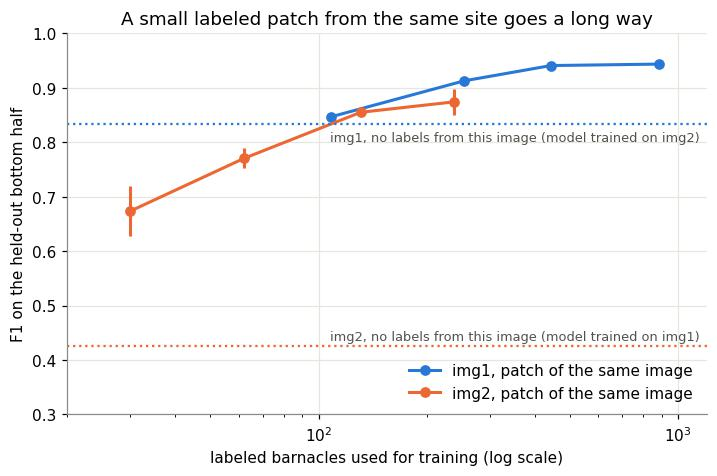

labeled barnacles  F1 mean  F1 min  F1 max  \
image labeled area                                               
img1  1/16                        108    0.846   0.840   0.853   
      1/8                         254    0.913   0.912   0.913   
      1/4                         443    0.941   0.935   0.946   
      1/2                         884    0.944   0.940   0.947   
img2  1/16                         30    0.674   0.627   0.720   
      1/8                          62    0.770   0.752   0.789   
      1/4                         131    0.855   0.849   0.861   
      1/2                         238    0.874   0.851   0.897   

                    count error mean  |count error| max  
image labeled area                                       
img1  1/16                    -0.195              0.205  
      1/8                     -0.088              0.094  
      1/4                     -0.026              0.033  
      1/2                      0.015              0.019  
img2  1/16                    -0.412              0.428  
      1/8                     -0.270              0.327  
      1/4                      0.082              0.088  
      1/2                     -0.028              0.038

In [6]:
budget = evaluate.budget_table(detections, held_out, labeled_counts, BUDGETS, SEEDS)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for (name, rows), color in zip(budget.groupby("image"), [evaluate.BLUE, evaluate.ORANGE]):
    ax.plot(rows["labeled barnacles"], rows["F1 mean"], "o-", color=color, label=f"{name}, patch of the same image")
    ax.vlines(rows["labeled barnacles"], rows["F1 min"], rows["F1 max"], color=color, linewidth=2)
for name, color in zip(samples, [evaluate.BLUE, evaluate.ORANGE]):
    other = "img2" if name == "img1" else "img1"
    # Score the bottom half only, like the curves; the cross model saw none of this image.
    cross = evaluate.kept(detections[f"cross/{other}->{name}"])
    truth = samples[name].points
    f1 = evaluate.score(cross[cross[:, 1] >= BOTTOM[1]], truth[truth[:, 1] >= BOTTOM[1]]).f1
    print(f"{name} bottom half, no labels from it: F1 {f1:.3f}")
    ax.axhline(f1, color=color, linestyle=":", linewidth=1.5)
    ax.annotate(f"{name}, no labels from this image (model trained on {other})", (1150, f1), xytext=(0, -11 if name == "img1" else 4),
                textcoords="offset points", ha="right", color="#52514e", fontsize=8.5)
ax.set_xscale("log")
ax.set_xlim(20, 1200)
ax.set_ylim(0.3, 1.0)
ax.set_xlabel("labeled barnacles used for training (log scale)")
ax.set_ylabel("F1 on the held-out bottom half")
ax.set_title("A small labeled patch from the same site goes a long way")
ax.legend(loc="lower right")
plt.show()

budget.round(3).set_index(["image", "labeled area"])

For img1, about 440 labeled barnacles (a quarter of the photo) gets F1 0.94 with a ~3% count error, and more labels barely help. img2 is harder, with fewer barnacles per patch and more shells and shiny rock around them. It gets to about 0.86 with ~130 labels. Tiny patches undercount: those models miss barnacles rather than invent them.

The test halves are small, especially img2's, so don't read too much into a couple of points either way. The overall takeaway still holds: labeling a few hundred barnacles is much less work than counting one photo, and it makes a big difference.

### Does training on both photos hurt?

If one shared model is going to cover many sites, adding another site's data shouldn't make it worse.

In [7]:
evaluate.pooled_table(detections, held_out, SEEDS)

F1 trained on this image only  F1 trained on both images
image seed                                                          
img1  0                             0.940                      0.947
      1                             0.947                      0.939
img2  0                             0.897                      0.899
      1                             0.851                      0.912

It doesn't. If anything it helps img2 (one of its runs goes from 0.85 to 0.91).

### What it still gets wrong

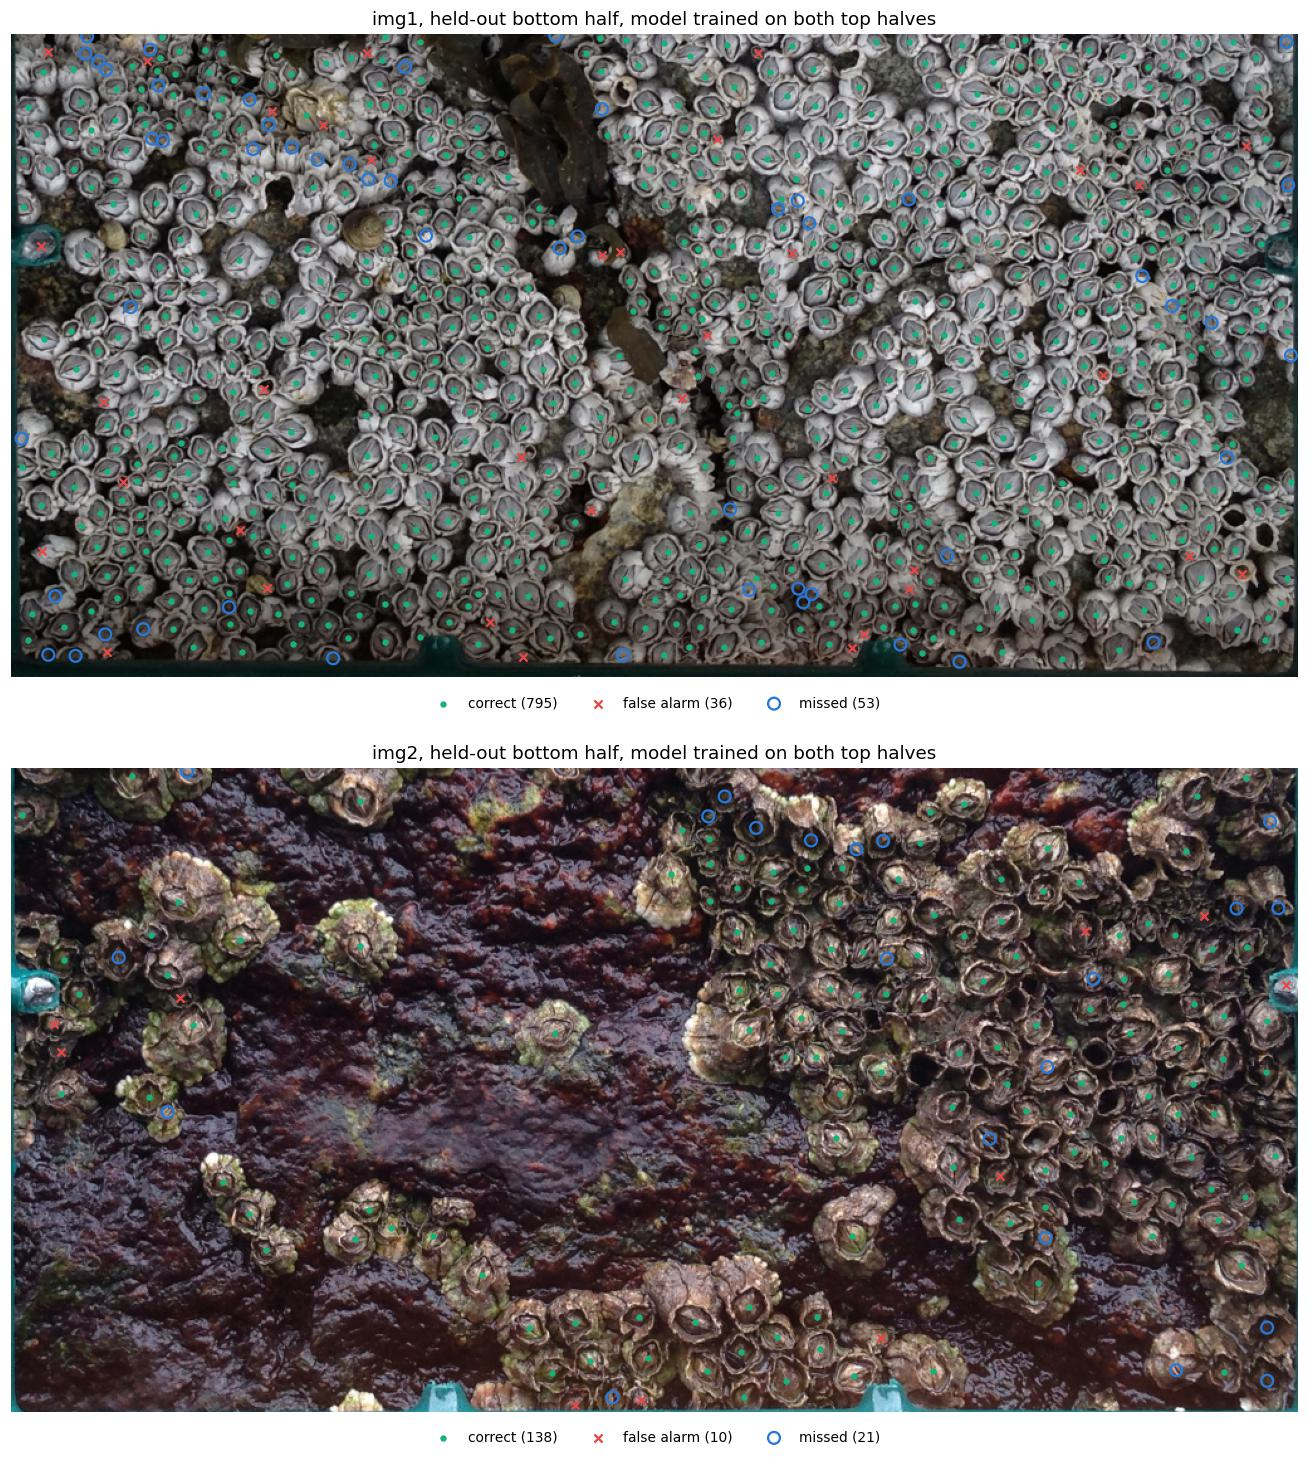

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 13.5))
for ax, (name, s) in zip(axes, samples.items()):
    image, truth = data.crop(s.image, s.points, BOTTOM)
    evaluate.show_errors(image, detections[f"pooled/{name}/seed0"], truth, ax,
                      title=f"{name}, held-out bottom half, model trained on both top halves")
fig.tight_layout()

Misses are mostly in dense clusters of tiny barnacles and on barnacles half hidden by a neighbor. False alarms are mostly empty or nearly closed shells, plus a bit of wire at the edges. Some "misses" are just a dot landing on the shell instead of the opening, which a person would accept. And the labels cover "almost all" barnacles, so some false alarms are probably real.

## Can the confidence tell a person where to look?

I simulated someone checking dots one at a time, starting with the ones the model was least sure about, and compared that to checking in random order.

F1
image dots checked                 
img1  84 (10% of barnacles)   0.964
      212 (25% of barnacles)  0.975
      424 (50% of barnacles)  0.985
img2  15 (10% of barnacles)   0.916
      39 (25% of barnacles)   0.932
      79 (50% of barnacles)   0.952

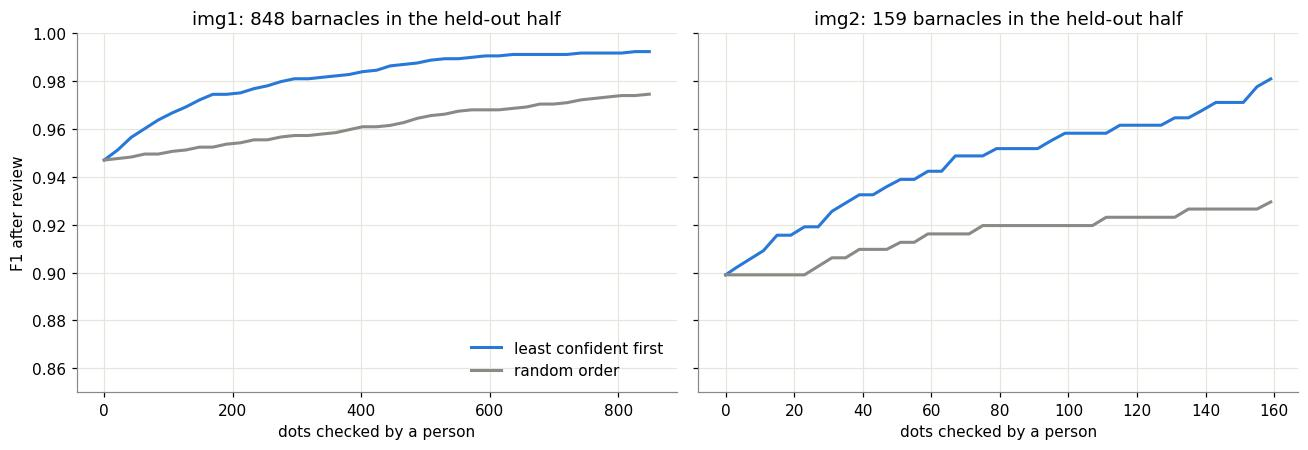

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, (name, s) in zip(axes, samples.items()):
    truth = held_out[name]
    det = detections[f"pooled/{name}/seed0"]
    checkpoints = np.unique(np.linspace(0, len(truth), 41).astype(int))
    ax.plot(checkpoints, evaluate.review_curve(det, truth, checkpoints), color=evaluate.BLUE, label="least confident first")
    ax.plot(checkpoints, evaluate.review_curve(det, truth, checkpoints, order="random"), color=evaluate.GRAY, label="random order")
    ax.set_title(f"{name}: {len(truth)} barnacles in the held-out half")
    ax.set_xlabel("dots checked by a person")
ax.set_ylim(0.85, 1.0)
axes[0].set_ylabel("F1 after review")
axes[0].legend(loc="lower right")
fig.tight_layout()

rows = []
for name, s in samples.items():
    truth = held_out[name]
    det = detections[f"pooled/{name}/seed0"]
    for fraction in (0.1, 0.25, 0.5):
        n = int(fraction * len(truth))
        rows.append({"image": name, "dots checked": f"{n} ({fraction:.0%} of barnacles)",
                     "F1": evaluate.review_curve(det, truth, [n])[0].round(3)})
pd.DataFrame(rows).set_index(["image", "dots checked"])

Checking the unsure dots first is clearly better than random. For img1, checking 84 dots takes F1 from 0.947 to 0.964. It's a modest gain, though. A lot of the remaining mistakes are ones the model is confident about, or barnacles it never put a dot near, so a real tool should also let you click to add missed ones. I didn't time anything, so I'm not claiming an actual speed-up yet.

## Conclusions

I think this is worth continuing:

- Finding the frame is basically solved for photos like these.
- The CNN works well on a site it has seen (F1 0.94 / 0.91), while the blob detector gets ~0.35.
- It doesn't reliably carry over to a new site, but labeling a few hundred barnacles there fixes most of that.
- Confidence is useful for deciding what a person should double-check.

How I'd use it: at each new site, label a patch of one photo, fine-tune the shared model, let it count the rest, and have someone review the overlays. Their corrections go back into training.

Next I'd want to:
1. Time manual counting against reviewing dots, to see the actual speed-up.
2. Get more photos from different sites, labeled with dots.
3. Report each count with a rough uncertainty range.

## What I learned

The biggest thing was how much choosing the right output mattered. Once I noticed the labels only mark live barnacles, the problem became "put a dot on each live one", and a heatmap network does that really simply. It gives you the count, the locations, and a confidence all at once. I hadn't used CenterNet-style training before, and it was cool to see such a small model learn to skip empty shells.

The other lesson was about metrics: the 7% count error on a model with F1 0.42 changed how I evaluated everything. Also, my first frame detector was cutting off the corners of the square. It looked fine by eye, and only testing it on a fake frame with a known size caught it.